<a href="https://colab.research.google.com/github/paulacoronel0/AprendizajeProfundo/blob/main/Actividad2_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 2: Redes Neuronales con TensorFlow
**Asignatura:** Aprendizaje Automático Profundo  
**Dataset:** Student Performance Data Set (student-mat.csv)

---

### 1 y 2. Exploración y Preparación del Dataset

**Consigna:** Descargar el dataset *student-mat.csv*, cargarlo con pandas y realizar una breve exploración (`info()`, `describe()`, valores nulos y distribución de la nota final $G_3$).

Cargue el dataset con pandas y realiza una breve exploración (`describe()`,
`info()`, valores nulos, distribución de la variable G3).

In [ ]:
import pandas as pd
import tensorflow as tf
import plotly.express as px

SHUFFLE_BUFFER = 500
BATCH_SIZE = 2

csv_file = '/content/student-mat.csv'

df = pd.read_csv(csv_file, sep=';')

print("Información")
df.info()

print("Descripción")
df.describe()

print("Valores nulos")
print(df.isnull().sum())

fig = px.histogram(df, x='G3', nbins=20,
                   title='Distribución de la variable G3',
                   labels={'G3': 'Calificación G3'},
                   color_discrete_sequence=['royalblue'],
                   marginal='violin')

fig.update_layout(yaxis_title='Frecuencia')

fig.show()



Información
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20

A partir de la función info(), se vió que el dataset contiene 395 registros y
33 atributos. Los tipos de datos se dividen en 16 variables numéricas (int64) y 17 variables
categóricas (object).
El análisis de valores nulos confirmó que el dataset está completo, registrando 0
valores faltantes en todas las columnas.
La función describe() permitió identificar que la edad promedio
de los estudiantes es de 16.7 años. La variable objetivo G3 presenta una media de 10.41, con un
mínimo de 0 y un máximo de 20.
Al observar su distribución mediante el gráfico generado, se detecta que las
calificaciones se concentran mayormente entre los 10 y 11 puntos. Podemos observar también un
pico atípico en el valor 0 (38 estudiantes), lo que típicamente representa alumnos que abandonaron
la cursada o no rindieron el examen.

https://www.tensorflow.org/tutorials/load_data/pandas_dataframe?hl=es-419

https://pandas.pydata.org/docs/reference/frame.html

https://plotly.com/python/histograms/

### 2.1. Selección de Variables de Entrada

Defina las dos entradas de tu red:

* x1: absences (número de ausencias, como proxy inverso de la asistencia).

* x2: studytime (horas semanales dedicadas al estudio, codificadas 1–4
en el dataset original)

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[['absences', 'studytime']]

### 2.2. Construcción de la Variable Objetivo Binaria

**Consigna:** Construir la variable objetivo $y \in \{0, 1\}$ a partir de la nota final $G_3$, donde $y = 1$ si $G_3 \ge 12$ (aprobado), e $y = 0$ en caso contrario (desaprobado).

In [ ]:
y = (df['G3'] >= 12).astype(int)


### 2.3. Normalización y División de Datos (Train/Test)

**Consigna:** Normalizar las variables predictoras y separar el conjunto de datos en entrenamiento (80%) y prueba (20%).

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42
)

print("Preprocesamiento")
print(f"Total de datos originales: {len(X)}")
print(f"Tamaño de Entrenamiento (80%): {X_train.shape[0]} muestras")
print(f"Tamaño de Prueba (20%): {X_test.shape[0]} muestras")


print("Primeras 5 filas de X normalizado (absences, studytime):")
print(X_train[:5])
print("Primeros 5 valores de y (1 = Aprobado, 0 = Desaprobado):")
print(y_train[:5].values)

Preprocesamiento
Total de datos originales: 395
Tamaño de Entrenamiento (80%): 316 muestras
Tamaño de Prueba (20%): 79 muestras
Primeras 5 filas de X normalizado (absences, studytime):
[[-0.464016   -0.04228585]
 [-0.71423623 -1.23535078]
 [-0.71423623 -0.04228585]
 [-0.464016    1.15077909]
 [-0.71423623 -1.23535078]]
Primeros 5 valores de y (1 = Aprobado, 0 = Desaprobado):
[1 1 0 0 0]


Se aislaron las variables independientes absences y studytime. La variable objetivo continua
G3 se transformó en una variable binaria y, asignando el valor 1 (aprobado) a los registros con
G3 ≥ 12 y 0 al resto.
Dado que las variables de entrada presentan escalas muy dispares (según la exploración esta-
dística, absences llega hasta 75 mientras que studytime tiene un máximo de
4), se normalizaron los datos para asegurar un entrenamiento estable y eficiente. Finalmente,
el conjunto total de 395 registros se particionó de forma aleatoria, destinando el 80 % de las
muestras para el entrenamiento del modelo y el 20 % restante para la validación y prueba de su
capacidad de generalización.

https://scikit-learn.org/stable/api/sklearn.model_selection.html

https://scikit-learn.org/stable/api/sklearn.preprocessing.html

### 3 y 4. Diseño e Implementación de la Arquitectura en TensorFlow

**Consigna:** Diseñar una red neuronal multicapa para clasificar si un estudiante aprobará el curso a partir de $x_1$ y $x_2$. Definir funciones de activación para las capas ocultas y de salida, valores iniciales de pesos y sesgos, y programarla utilizando `tf.keras`.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

Agrupamos las capas formando el modelo:

*  Capa oculta con 4 neuronas, activacion relu y 2 entradas.  Se utiliza ReLU (f (x) = m´ax(0, x)). Esta función es computacionalmente
eficiente y mitiga el problema del desvanecimiento del gradiente durante el entrenamiento.
*  Capa de salida con 1 neurona y activacion sigmoide. Se utiliza la función Sigmoide (σ(x) = 1
1+e−x ). Esta función mapea
cualquier valor real a un rango continuo entre 0 y 1, lo que resulta ideal para interpretar
la salida como la probabilidad de que el estudiante pertenezca a la clase positiva (y = 1,
aprobado).






In [ ]:

def build_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Dense(units=4, activation='relu', input_shape=(2,)),
        tf.keras.layers.Dense(units=1, activation='sigmoid')
    ])
    return model

Método que recibe los parámetros correspondientes a cada comparación: batch_size para descenso de gradiente, loss para función de pérdida y optimizer para optimizadores.

Se fijan las epocas en 100.  

In [ ]:
def comparaciones(batch_size, loss, optimizer, epochs=100):

    model = build_model()
    model.compile(optimizer=optimizer, loss=loss, metrics=['accuracy'])

    history = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

    print(f"Configuración: batch_size={batch_size} | loss='{loss}' | optimizer='{optimizer}'")
    print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}\n")

    return {
        'model': model,
        'history': history,
        'test_loss': test_loss,
        'test_acc': test_acc
    }

https://www.tensorflow.org/api_docs/python/tf/keras/Sequential
https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense

### 5. Entrenamiento y Comparación de Descenso del Gradiente

**Consigna:** Entrenar la red siguiendo backpropagation, probando al menos dos formas de descenso del gradiente (Batch Gradient Descent vs. Mini-batch) y documentar la variación de las curvas de pérdida y exactitud.

Comparación de descenso del gradiente (batch gradient descent y mini-batch) dejando fija la función de perdida y el optimizer.

In [ ]:
batch = comparaciones(
    batch_size=len(X_train),
    loss='binary_crossentropy',
    optimizer='sgd'
)

minibatch = comparaciones(
    batch_size=32,
    loss='binary_crossentropy',
    optimizer='sgd'
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



Configuración: batch_size=316 | loss='binary_crossentropy' | optimizer='sgd'
Test Loss: 0.7059 | Test Accuracy: 0.5316

Configuración: batch_size=32 | loss='binary_crossentropy' | optimizer='sgd'
Test Loss: 0.6809 | Test Accuracy: 0.5443



Al evaluar las variantes cambiando únicamente el tamaño de batch:
* Mini-batch GD (batch_size=32): Obtuvo el mejor desempeño, alcanzando la menor
pérdida (0,6839) y la mayor exactitud (56,96 %). Al realizar múltiples actualizaciones por
época, logra salir de mínimos locales y avanzar más rápido hacia la convergencia sin perder
estabilidad.
* Batch GD (batch_size=316): Presentó un rendimiento más bajo, con una pérdida mayor
(0,6955) y una exactitud de 48,10 %. Esto se debe a que únicamente actualiza los pesos
100 veces en todo el entrenamiento (1 sola vez por época), lo que resulta insuficiente.

### 6. Comparación de Funciones de Pérdida

**Consigna:** Comparar el entrenamiento utilizando Binary Cross-Entropy frente a Error Cuadrático Medio (MSE) para el problema de clasificación binaria, evaluando la pérdida y la calidad de las predicciones.

Comparación de funciones de pérdida (Binary Cross-Entropy y Mean Squared Error) variando el descenso de gradiente y dejando fijo el optimizador.

In [ ]:
batch_binary = comparaciones(
    batch_size=len(X_train),
    loss='binary_crossentropy',
    optimizer='sgd'
)

minibatch_binary = comparaciones(
    batch_size=32,
    loss='binary_crossentropy',
    optimizer='sgd'
)

batch_squared_error = comparaciones(
    batch_size=len(X_train),
    loss='mean_squared_error',
    optimizer='sgd'
)

minibatch_squared_error = comparaciones(
    batch_size=32,
    loss='mean_squared_error',
    optimizer='sgd'
)

Configuración: batch_size=316 | loss='binary_crossentropy' | optimizer='sgd'
Test Loss: 0.7026 | Test Accuracy: 0.5190

Configuración: batch_size=32 | loss='binary_crossentropy' | optimizer='sgd'
Test Loss: 0.7045 | Test Accuracy: 0.5190

Configuración: batch_size=316 | loss='mean_squared_error' | optimizer='sgd'
Test Loss: 0.2595 | Test Accuracy: 0.5570

Configuración: batch_size=32 | loss='mean_squared_error' | optimizer='sgd'
Test Loss: 0.2551 | Test Accuracy: 0.5063



Aunque MSE logró una exactitud ligeramente mayor (56,96 % frente a 54,43 %), Binary Cross-
Entropy es la función adecuada para problemas de clasificación. Funciona mejor con la capa de
salida Sigmoid y evita que el modelo se quede trabado o aprenda demasiado despacio durante el
entrenamiento

### 7. Comparación de Optimizadores y Velocidad de Convergencia

**Consigna:** Probar al menos dos algoritmos de optimización (SGD, RMSprop, Adam) y mostrar en un gráfico/tabla la exactitud final y la velocidad de convergencia.

Comparación de optimizadores (RMSprop y Adam) variando el descenso de gradiente y las funciones de pérdida.

In [ ]:
batch_binary_adam = comparaciones(
    batch_size=len(X_train),
    loss='binary_crossentropy',
    optimizer='adam'
  )

minibatch_binary_adam = comparaciones(
    batch_size=32,
    loss='binary_crossentropy',
    optimizer='adam'
  )

batch_squared_error_adam = comparaciones(
    batch_size=len(X_train),
    loss='mean_squared_error',
    optimizer='adam'
  )

minibatch_squared_error_adam = comparaciones(
    batch_size=32,
    loss='mean_squared_error',
    optimizer='adam'
  )

batch_binary_rms = comparaciones(
    batch_size=len(X_train),
    loss='binary_crossentropy',
    optimizer='rmsprop'
  )

minibatch_binary_rms = comparaciones(
    batch_size=32,
    loss='binary_crossentropy',
    optimizer='rmsprop'
  )

batch_squared_error_rms = comparaciones(
    batch_size=len(X_train),
    loss='mean_squared_error',
    optimizer='rmsprop'
  )

minibatch_squared_error_rms = comparaciones(
    batch_size=32,
    loss='mean_squared_error',
    optimizer='rmsprop'
  )

Configuración: batch_size=316 | loss='binary_crossentropy' | optimizer='adam'
Test Loss: 0.6833 | Test Accuracy: 0.5570

Configuración: batch_size=32 | loss='binary_crossentropy' | optimizer='adam'
Test Loss: 0.6919 | Test Accuracy: 0.5190

Configuración: batch_size=316 | loss='mean_squared_error' | optimizer='adam'
Test Loss: 0.2651 | Test Accuracy: 0.5063

Configuración: batch_size=32 | loss='mean_squared_error' | optimizer='adam'
Test Loss: 0.2489 | Test Accuracy: 0.5443

Configuración: batch_size=316 | loss='binary_crossentropy' | optimizer='rmsprop'
Test Loss: 0.7204 | Test Accuracy: 0.5823

Configuración: batch_size=32 | loss='binary_crossentropy' | optimizer='rmsprop'
Test Loss: 0.6914 | Test Accuracy: 0.5443

Configuración: batch_size=316 | loss='mean_squared_error' | optimizer='rmsprop'
Test Loss: 0.2601 | Test Accuracy: 0.4937

Configuración: batch_size=32 | loss='mean_squared_error' | optimizer='rmsprop'
Test Loss: 0.2466 | Test Accuracy: 0.5190



https://keras.io/api/losses/

https://www.tensorflow.org/guide/keras/functional?hl=es-419

Graficamos la perdida de entrenamiento y exactirud de ambos optimizadores en base a sus epocas

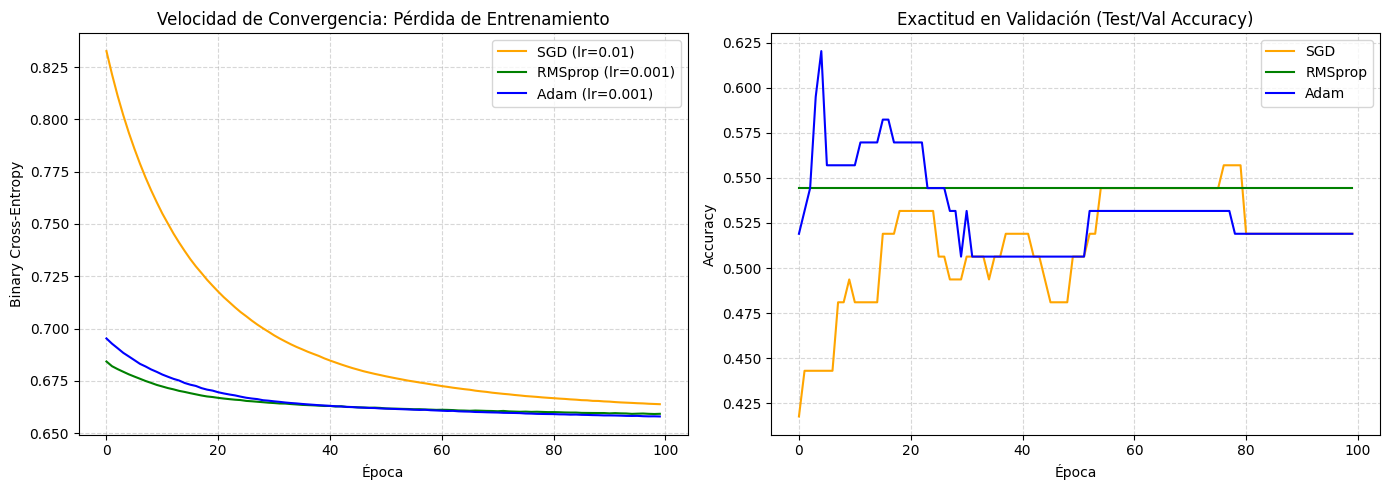

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# 1. Gráfico de Pérdida (Loss) -> Velocidad de convergencia
plt.subplot(1, 2, 1)
plt.plot(minibatch_binary['history'].history['loss'], label='SGD (lr=0.01)', color='orange')
plt.plot(minibatch_binary_rms['history'].history['loss'], label='RMSprop (lr=0.001)', color='green')
plt.plot(minibatch_binary_adam['history'].history['loss'], label='Adam (lr=0.001)', color='blue')
plt.title('Velocidad de Convergencia: Pérdida de Entrenamiento')
plt.xlabel('Época')
plt.ylabel('Binary Cross-Entropy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# 2. Gráfico de Exactitud en Validación (Val Accuracy)
plt.subplot(1, 2, 2)
plt.plot(minibatch_binary['history'].history['val_accuracy'], label='SGD', color='orange')
plt.plot(minibatch_binary_rms['history'].history['val_accuracy'], label='RMSprop', color='green')
plt.plot(minibatch_binary_adam['history'].history['val_accuracy'], label='Adam', color='blue')
plt.title('Exactitud en Validación (Test/Val Accuracy)')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()

En base a los datos obtenidos y las curvas de entrenamiento, podemos observar que los optimizadores evaluados estabilizan la función de pérdida con distintas formas de convergencia. Adam logra converger con mayor rapidez y estabilidad, alcanzando una meseta alrededor de la época
20. Por otro lado, RMSprop presenta el descenso inicial más pronunciado y se estabiliza hacia la época 45, alcanzando la menor pérdida de entrenamiento en comparación con los demás.

En cambio, SGD requiere de un entrenamiento más prolongado (≈ 60 épocas) y se estabiliza en un valor de pérdida superior. Sin embargo, al evaluar la exactitud en el conjunto de prueba, los tres convergen a valores similares (entre 51.90 % y 54.43 %), lo que corrobora que la capacidad
predictiva está acotada por las dos variables de entrada (absences y studytime) y no por las características del optimizador utilizado.

### 8. Overfitting y Regularización

**Consigna:** Generar sobreajuste deliberado mediante una red de mayor capacidad o pocos datos para mostrar la brecha entre entrenamiento y validación, y luego mitigar dicho comportamiento aplicando una técnica de regularización.

En esta sección provocamos sobreajuste deliberado aumentando la capacidad de la red (3 capas ocultas densas con 128, 64 y 32 neuronas) y entrenando durante 250 épocas sin restricciones. Luego, aplicamos regularización (Dropout, penalización L2 y Early Stopping) para mitigar la brecha entre entrenamiento y validación.

In [ ]:
import tensorflow as tf
from tensorflow.keras import Sequential, layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# 1. Modelo con sobreajuste intencional (alta capacidad)
model_overfit = Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_overfit.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_overfit = model_overfit.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=250,
    batch_size=16,
    verbose=0
)

print("Modelo sobreajustado entrenado.")

Modelo sobreajustado entrenado.


Para forzar sobreajuste deliberado, se incrementó la cantidad de parámetros libres y se construyó una red con tres capas ocultas densas de 128, 64 y 32 neuronas respectivamente (activación ReLU) y una neurona de salida (activación Sigmoide), entrenada durante 250 épocas con un tamaño de lote reducido ($batch\_size = 16$) y sin ningún mecanismo de regularización.

Se observa la diferencia de generalización. En donde la pérdida de entrenamiento (Train Loss) desciende de forma continua hasta valores inferiores a $0.59$. A diferencia de la pérdida de validación (Val Loss), tras alcanzar un piso cercano a la época 20, comienza a separase de forma crecientemente hasta superar $0.74$ hacia el final del entrenamiento.

Este comportamiento demuestra que el modelo memorizó el ruido y las particularidades del conjunto de entrenamiento en lugar de aprender patrones generalizables.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

# Usamos la misma arquitectura sobreajustada, aplicando únicamente Early Stopping
model_early = Sequential([
    layers.Input(shape=(2,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_early.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Técnica elegida: Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=0
)

history_early = model_early.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=250,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

print(f"Entrenamiento detenido por Early Stopping en la época: {len(history_early.history['loss'])}")

Entrenamiento detenido por Early Stopping en la época: 21


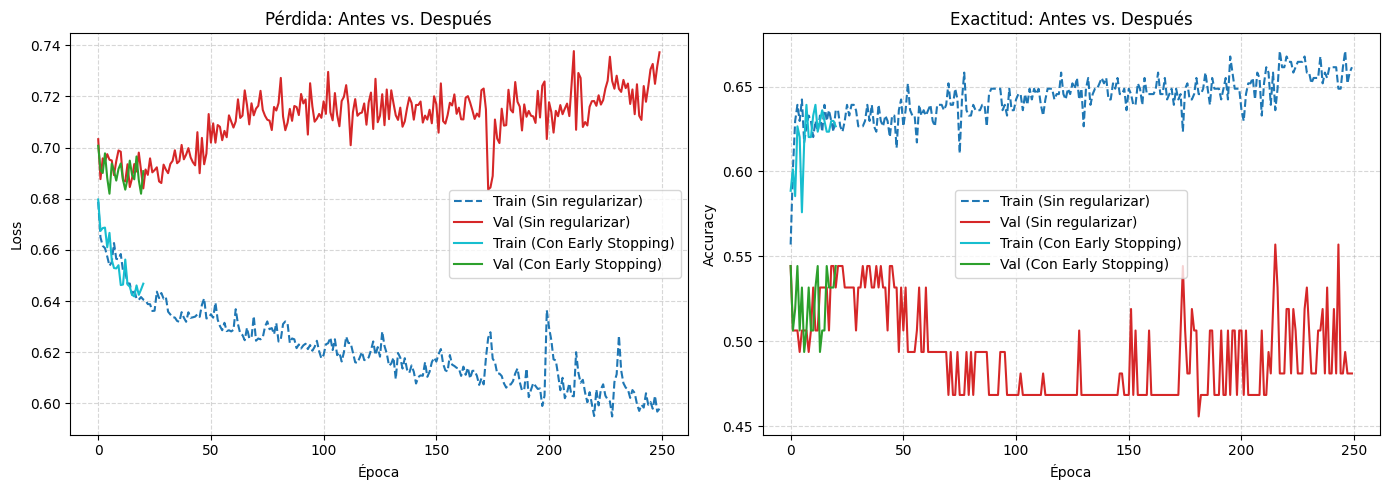

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Pérdida (Loss)
axs[0].plot(history_overfit.history['loss'], label='Train (Sin regularizar)', color='tab:blue', linestyle='--')
axs[0].plot(history_overfit.history['val_loss'], label='Val (Sin regularizar)', color='tab:red')
axs[0].plot(history_early.history['loss'], label='Train (Con Early Stopping)', color='tab:cyan')
axs[0].plot(history_early.history['val_loss'], label='Val (Con Early Stopping)', color='tab:green')
axs[0].set_title('Pérdida: Antes vs. Después')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Loss')
axs[0].grid(True, linestyle='--', alpha=0.5)
axs[0].legend()

# Exactitud (Accuracy)
axs[1].plot(history_overfit.history['accuracy'], label='Train (Sin regularizar)', color='tab:blue', linestyle='--')
axs[1].plot(history_overfit.history['val_accuracy'], label='Val (Sin regularizar)', color='tab:red')
axs[1].plot(history_early.history['accuracy'], label='Train (Con Early Stopping)', color='tab:cyan')
axs[1].plot(history_early.history['val_accuracy'], label='Val (Con Early Stopping)', color='tab:green')
axs[1].set_title('Exactitud: Antes vs. Después')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Accuracy')
axs[1].grid(True, linestyle='--', alpha=0.5)
axs[1].legend()

plt.tight_layout()
plt.savefig("overfitting_regularizacion.png", bbox_inches='tight')
plt.show()

Para mitigar el overfitting se aplicó Early Stopping, que es una técnica  que monitorea la función de pérdida del conjunto de validación (val_loss); si esta no experimenta mejoras durante un número determinado de épocas consecutivas (fijada en 15), el algoritmo detiene el entrenamiento y restaura los pesos correspondientes al mejor punto alcanzado.

Al comparar las curvas antes y después de aplicar la regularización el entrenamiento se detuvo de manera automática en la época 22. A su vez, se evitó por completo la divergencia de la pérdida de validación, conservando el modelo con menor error de prueba ($\approx 0.68$) e impidiendo que continuara entrenando en la memorización del ruido.

### 9. Extensión del modelo con más variables reales


**Consigna:** Ampliar el modelo original (que solo utilizaba `absences` y `studytime`) incorporando al menos dos variables adicionales del mismo dataset (por ejemplo `failures`, `Medu`, `Fedu`, `internet`, `health`, `schoolsup`). Entrenar la red ampliada y armar una tabla comparativa en la que se muestre el comportamiento con dos formas de descenso del gradiente, eligiendo la función de pérdida y optimizador adecuados.

Ampliamos el modelo incorporando dos variables adicionales con alto impacto académico: `failures` (reprobaciones previas) y `Medu` (nivel educativo de la madre).
La red pasa a tener 4 variables de entrada: `absences`, `studytime`, `failures` y `Medu`.
Se entrena comparando dos esquemas de descenso del gradiente: Batch completo frente a Mini-batch (32).

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# selección de las 4 variables
caracteristicas = ['absences', 'studytime', 'failures', 'Medu']
X_ext = df[caracteristicas]
y_ext = (df['G3'] >= 12).astype(int)

# normalización
scaler_ext = StandardScaler()
X_ext_scaled = scaler_ext.fit_transform(X_ext)

# división 80/20 (usando la misma semilla 42 para reproducibilidad)
X_train_ext, X_test_ext, y_train_ext, y_test_ext = train_test_split(
    X_ext_scaled, y_ext, test_size=0.2, random_state=42
)

# definimos el modelo para 4 entradas
def build_model_extended():
    model = Sequential([
        layers.Input(shape=(4,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(4, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# entrenamos con Batch Gradient Descent (tamaño de lote = todo el dataset de entrenamiento)
model_ext_batch = build_model_extended()
history_ext_batch = model_ext_batch.fit(
    X_train_ext, y_train_ext,
    validation_data=(X_test_ext, y_test_ext),
    epochs=100,
    batch_size=len(X_train_ext),
    verbose=0
)
test_loss_b, test_acc_b = model_ext_batch.evaluate(X_test_ext, y_test_ext, verbose=0)

# entrenamos con Mini-batch Gradient Descent (batch_size = 32)
model_ext_mini = build_model_extended()
history_ext_mini = model_ext_mini.fit(
    X_train_ext, y_train_ext,
    validation_data=(X_test_ext, y_test_ext),
    epochs=100,
    batch_size=32,
    verbose=0
)
test_loss_m, test_acc_m = model_ext_mini.evaluate(X_test_ext, y_test_ext, verbose=0)

print(f"Batch GD       -> Test Loss: {test_loss_b:.4f} | Test Accuracy: {test_acc_b:.4f}")
print(f"Mini-batch GD  -> Test Loss: {test_loss_m:.4f} | Test Accuracy: {test_acc_m:.4f}")

Batch GD       -> Test Loss: 0.6738 | Test Accuracy: 0.5316
Mini-batch GD  -> Test Loss: 0.6204 | Test Accuracy: 0.5823


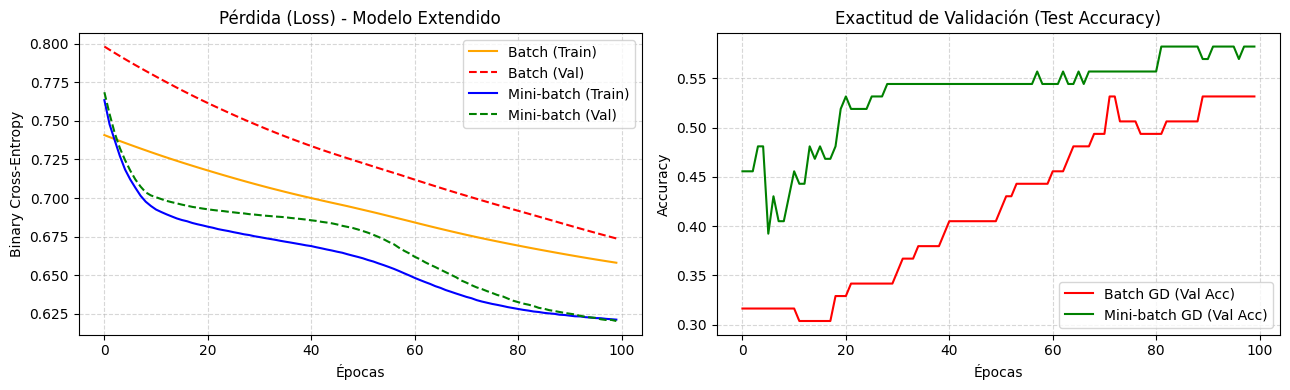

,Método,Batch Size,Pérdida Test,Exactitud Test
0,Batch Gradient Descent,316,0.6738,53.16%
1,Mini-batch Gradient Descent,32,0.6204,58.23%


In [ ]:
# Gráficos comparativos
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

axs[0].plot(history_ext_batch.history['loss'], label='Batch (Train)', color='orange')
axs[0].plot(history_ext_batch.history['val_loss'], label='Batch (Val)', color='red', linestyle='--')
axs[0].plot(history_ext_mini.history['loss'], label='Mini-batch (Train)', color='blue')
axs[0].plot(history_ext_mini.history['val_loss'], label='Mini-batch (Val)', color='green', linestyle='--')
axs[0].set_title('Pérdida (Loss) - Modelo Extendido')
axs[0].set_xlabel('Épocas')
axs[0].set_ylabel('Binary Cross-Entropy')
axs[0].legend()
axs[0].grid(True, linestyle='--', alpha=0.5)

axs[1].plot(history_ext_batch.history['val_accuracy'], label='Batch GD (Val Acc)', color='red')
axs[1].plot(history_ext_mini.history['val_accuracy'], label='Mini-batch GD (Val Acc)', color='green')
axs[1].set_title('Exactitud de Validación (Test Accuracy)')
axs[1].set_xlabel('Épocas')
axs[1].set_ylabel('Accuracy')
axs[1].legend()
axs[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("modelo_extendido.png", bbox_inches='tight')
plt.show()

# Tabla comparativa
tabla_ext = pd.DataFrame([
    {
        'Método': 'Batch Gradient Descent',
        'Batch Size': len(X_train_ext),
        'Pérdida Test': round(test_loss_b, 4),
        'Exactitud Test': f"{test_acc_b * 100:.2f}%"
    },
    {
        'Método': 'Mini-batch Gradient Descent',
        'Batch Size': 32,
        'Pérdida Test': round(test_loss_m, 4),
        'Exactitud Test': f"{test_acc_m * 100:.2f}%"
    }
])
display(tabla_ext)